In [1]:
import cv2 as cv, numpy as np, matplotlib.pyplot as plt, glob, os

tmpl = cv.imread('../images/pcbs/AECC1.jpg')
tg = cv.cvtColor(tmpl, cv.COLOR_BGR2GRAY)
sift = cv2_sift = cv.SIFT_create()
kp_t, des_t = sift.detectAndCompute(tg, None)

def align(path, show_matches=False):
    img = cv.imread(path); ig = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
    kp_i, des_i = sift.detectAndCompute(ig, None)
    knn = cv.BFMatcher().knnMatch(des_i, des_t, k=2)
    good = [m for m, n in knn if m.distance < 0.75 * n.distance]          # Lowe's ratio test
    src = np.float32([kp_i[m.queryIdx].pt for m in good]).reshape(-1, 1, 2)
    dst = np.float32([kp_t[m.trainIdx].pt for m in good]).reshape(-1, 1, 2)
    H, inl = cv.findHomography(src, dst, cv.RANSAC, 5.0)
    warped = cv.warpPerspective(img, H, (tmpl.shape[1], tmpl.shape[0]))
    diff = cv.absdiff(cv.cvtColor(warped, cv.COLOR_BGR2GRAY), tg)
    print(f"{os.path.basename(path)}: {len(kp_i)} keypoints, {len(good)} good matches, {int(inl.sum())} RANSAC inliers")
    matches_img = cv.drawMatches(img, kp_i, tmpl, kp_t, [m for m, k in zip(good, inl.ravel()) if k], None,
                                 flags=cv.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
    return warped, diff, matches_img

AAAA1.jpg: 2414 keypoints, 51 good matches, 18 RANSAC inliers


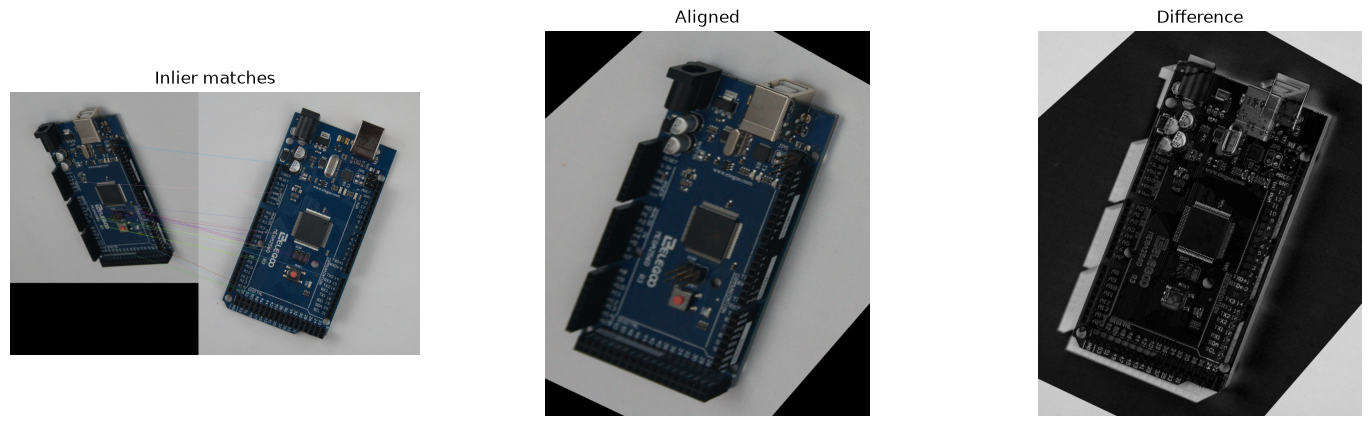

In [3]:
files = sorted(glob.glob('../images/pcbs/*'))
warped, diff, matches_img = align(files[0])
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
for a, im_, t in zip(ax, [matches_img, warped, diff], ['Inlier matches', 'Aligned', 'Difference']):
    a.imshow(cv.cvtColor(im_, cv.COLOR_BGR2RGB) if im_.ndim == 3 else im_, cmap='gray'); a.set_title(t); a.axis('off')
plt.show()

AAAA1.jpg: 2414 keypoints, 51 good matches, 18 RANSAC inliers
ADAD1.jpg: 8486 keypoints, 369 good matches, 194 RANSAC inliers
AECC1.jpg: 14272 keypoints, 14272 good matches, 14272 RANSAC inliers
AECC2.jpg: 12315 keypoints, 4322 good matches, 3847 RANSAC inliers
AECC3.jpg: 15198 keypoints, 5629 good matches, 5006 RANSAC inliers
AECC4.jpg: 11610 keypoints, 3830 good matches, 3402 RANSAC inliers


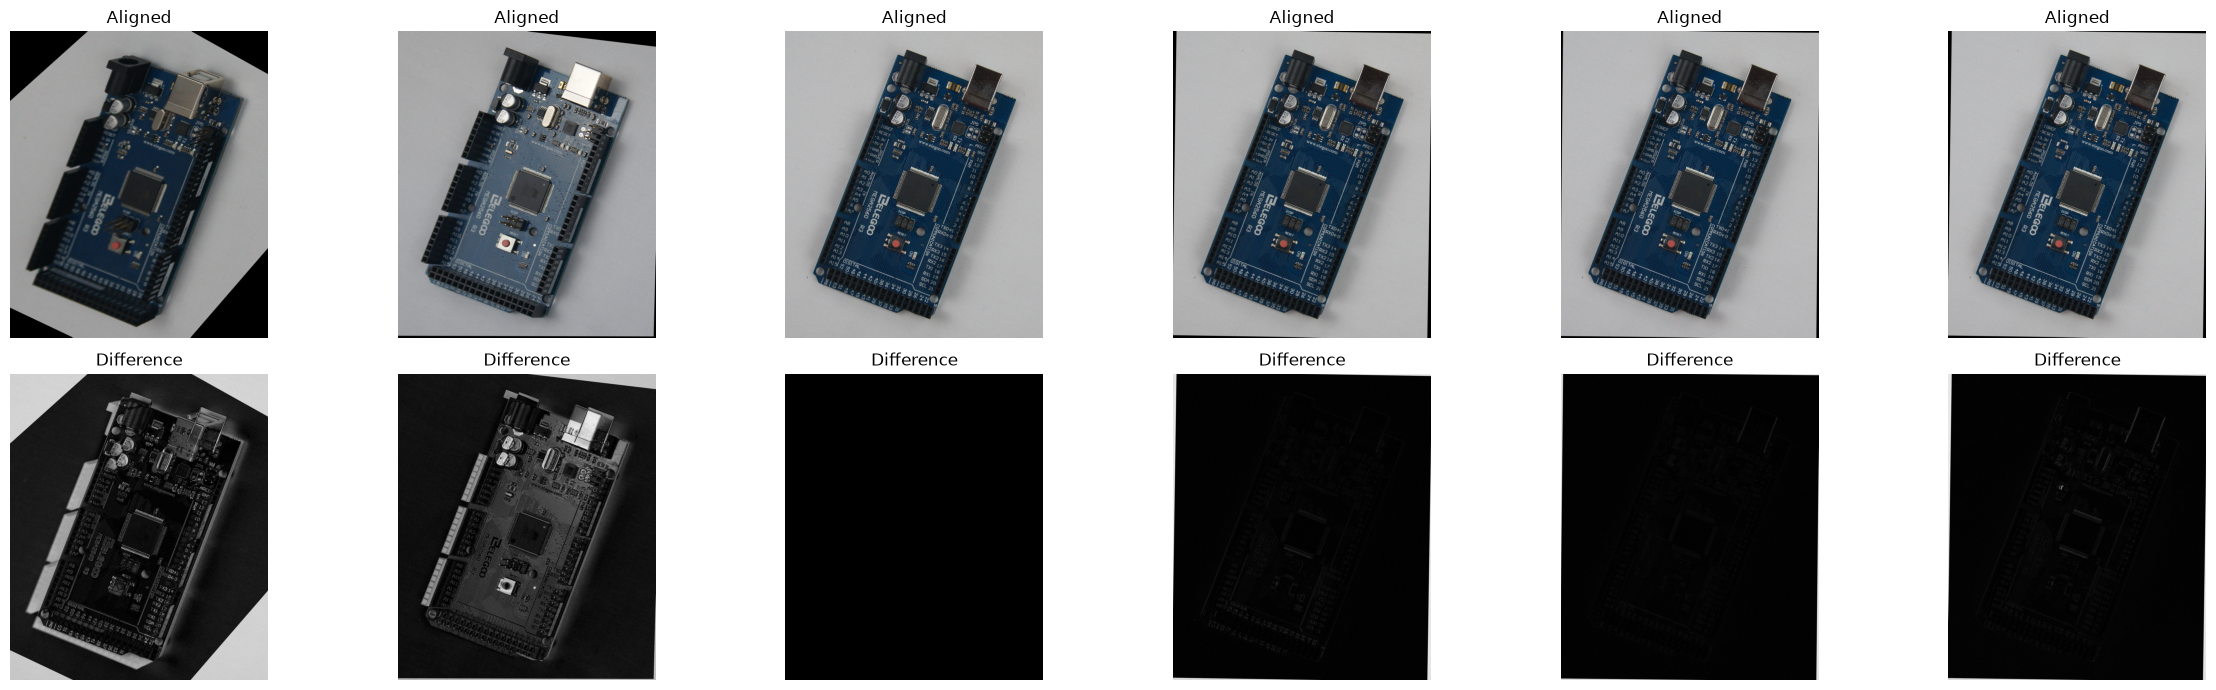

In [4]:
n = len(files)
fig, ax = plt.subplots(2, n, figsize=(4*n, 7), squeeze=False)
for k, f in enumerate(files):
    w_, d_, _ = align(f)
    ax[0, k].imshow(cv.cvtColor(w_, cv.COLOR_BGR2RGB)); ax[0, k].set_title('Aligned'); ax[0, k].axis('off')
    ax[1, k].imshow(d_, cmap='gray'); ax[1, k].set_title('Difference'); ax[1, k].axis('off')
plt.tight_layout(); plt.show()